# 05 · Explainability: SHAP and LIME
Implemented in `src/explain.py`.

In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.max_columns', 40, 'display.width', 160)
T = '../reports/tables/'; F = '../reports/figures/'
pd.read_csv(T+'shap_importance.csv', index_col=0).round(4).head(15)

,Slight,Serious,Fatal,overall
n_vehicles,0.1889,0.1159,0.2343,0.1797
speed_band,0.0402,0.0047,0.2239,0.0896
h_cell_n,0.0627,0.0139,0.1612,0.0793
speed_limit,0.0519,0.0100,0.1417,0.0679
1st_Road_Class,0.0417,0.0062,0.1199,0.0560
Junction_Detail,0.0384,0.0114,0.1019,0.0506
h_la_ksi_rate,0.0520,0.0695,0.0125,0.0447
hour_cos,0.0452,0.0164,0.0648,0.0421
Police_Force,0.0157,0.0519,0.0318,0.0331
h_cell_ksi_rate,0.0323,0.0148,0.0458,0.0310


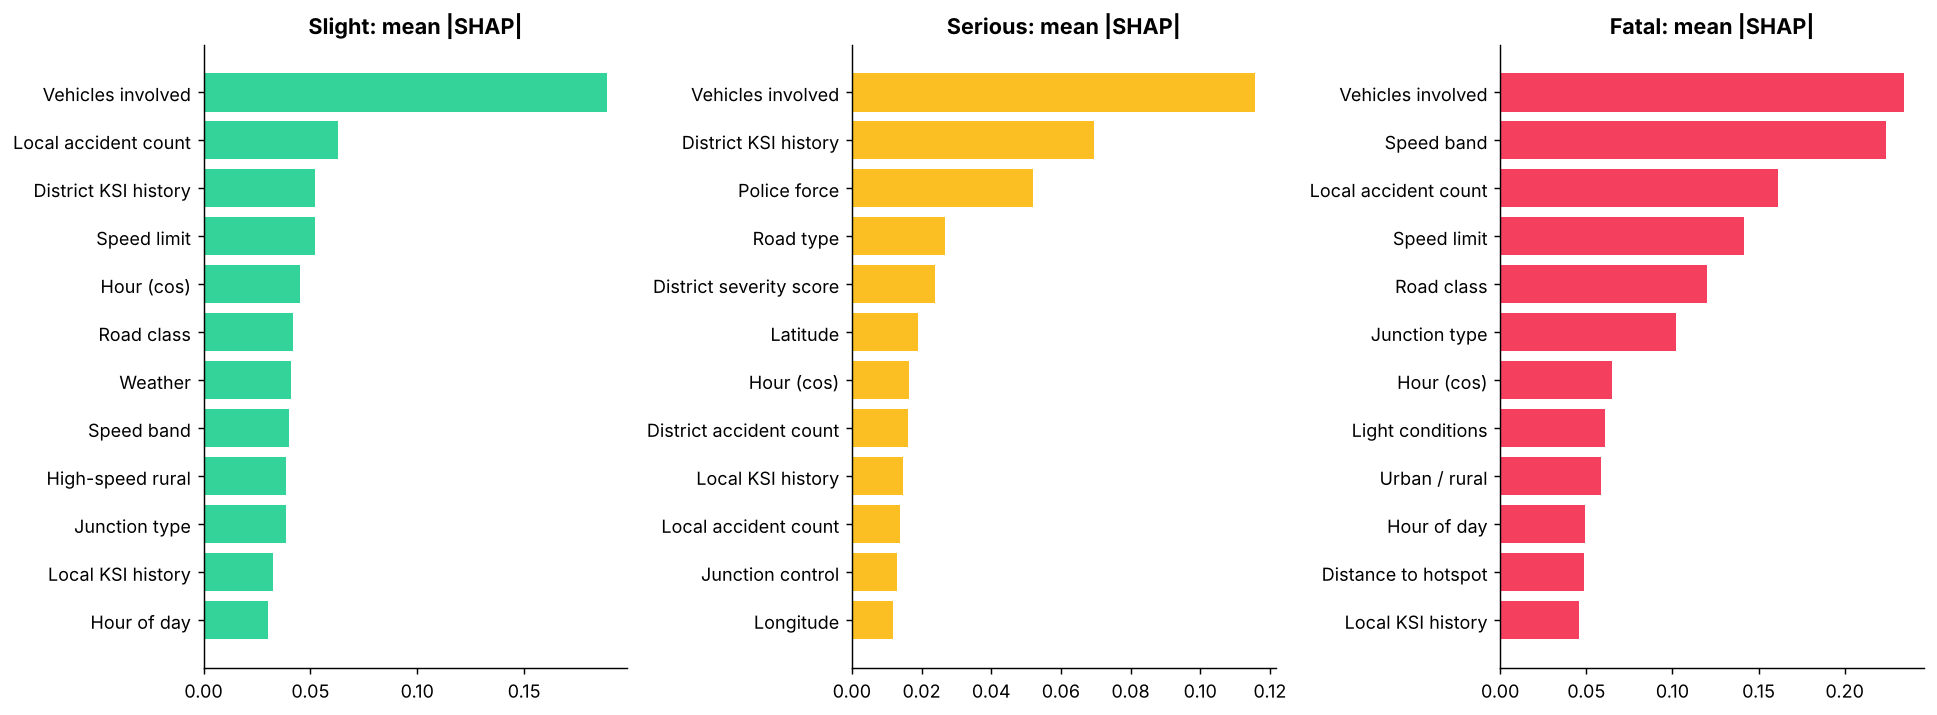

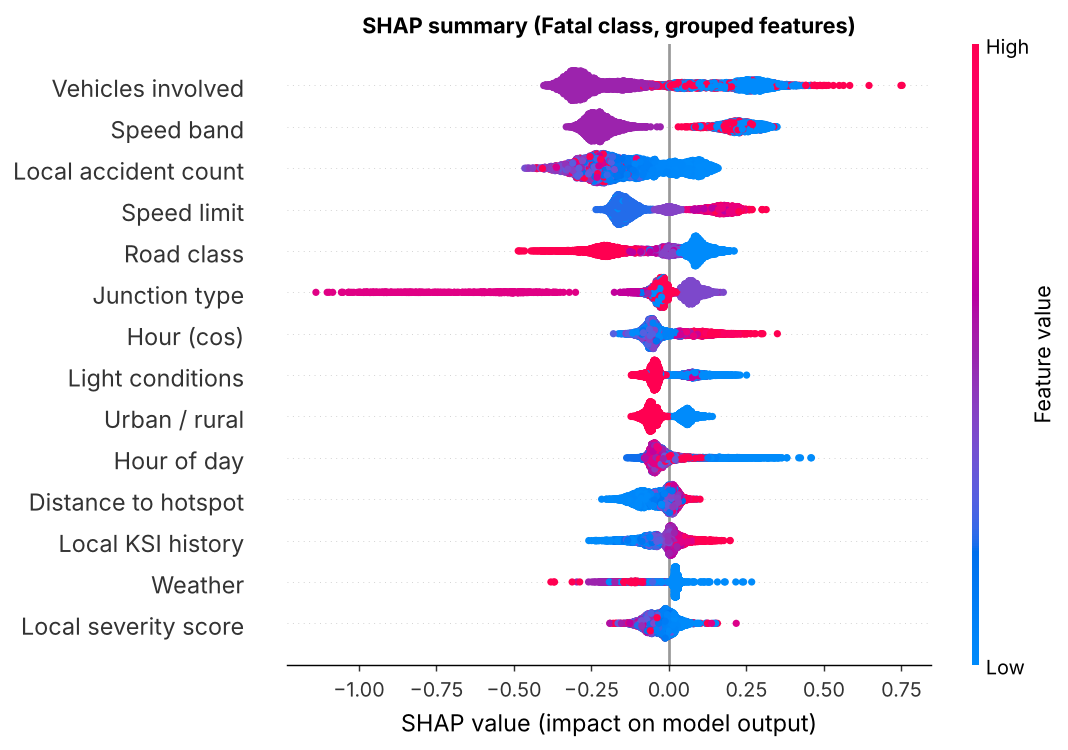

In [2]:
display(Image(F+'20_shap_importance_per_class.png')); display(Image(F+'21_shap_beeswarm_fatal.png'))

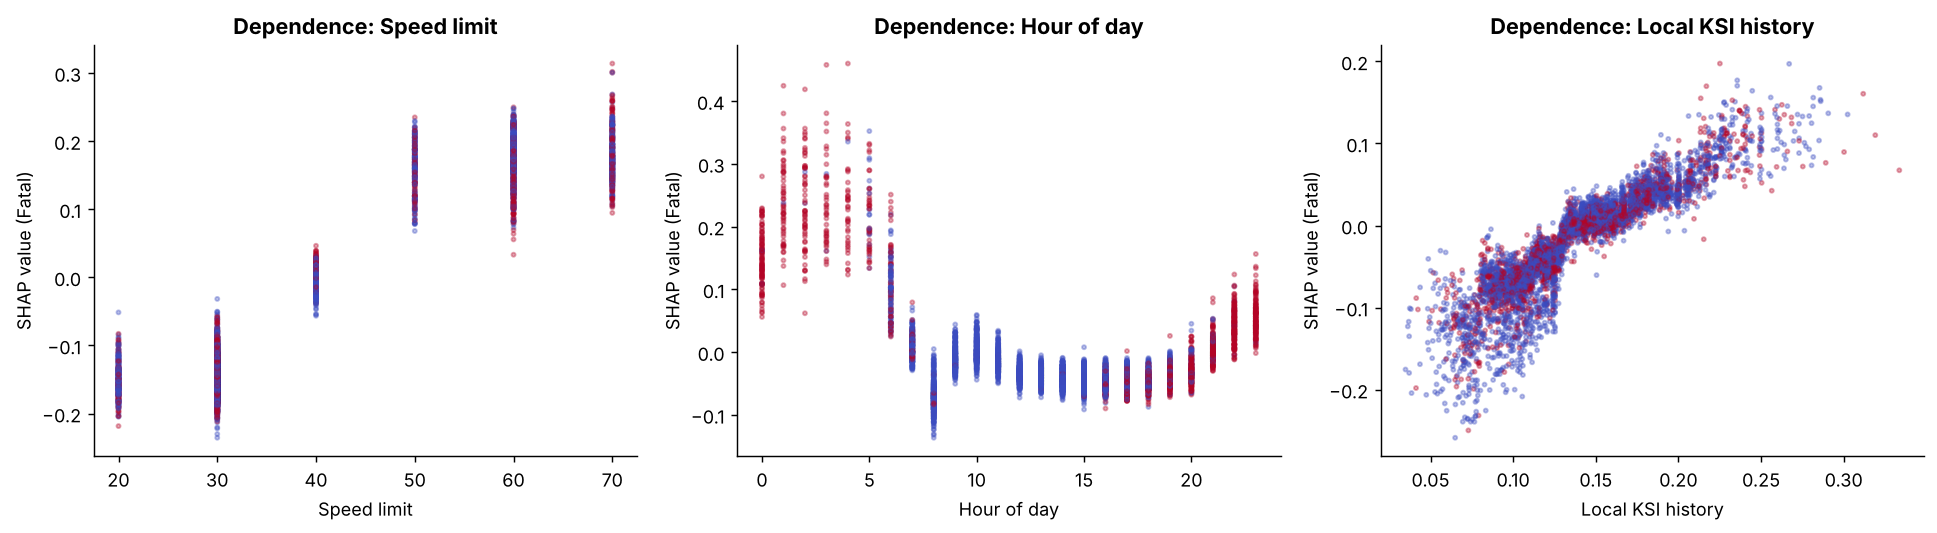

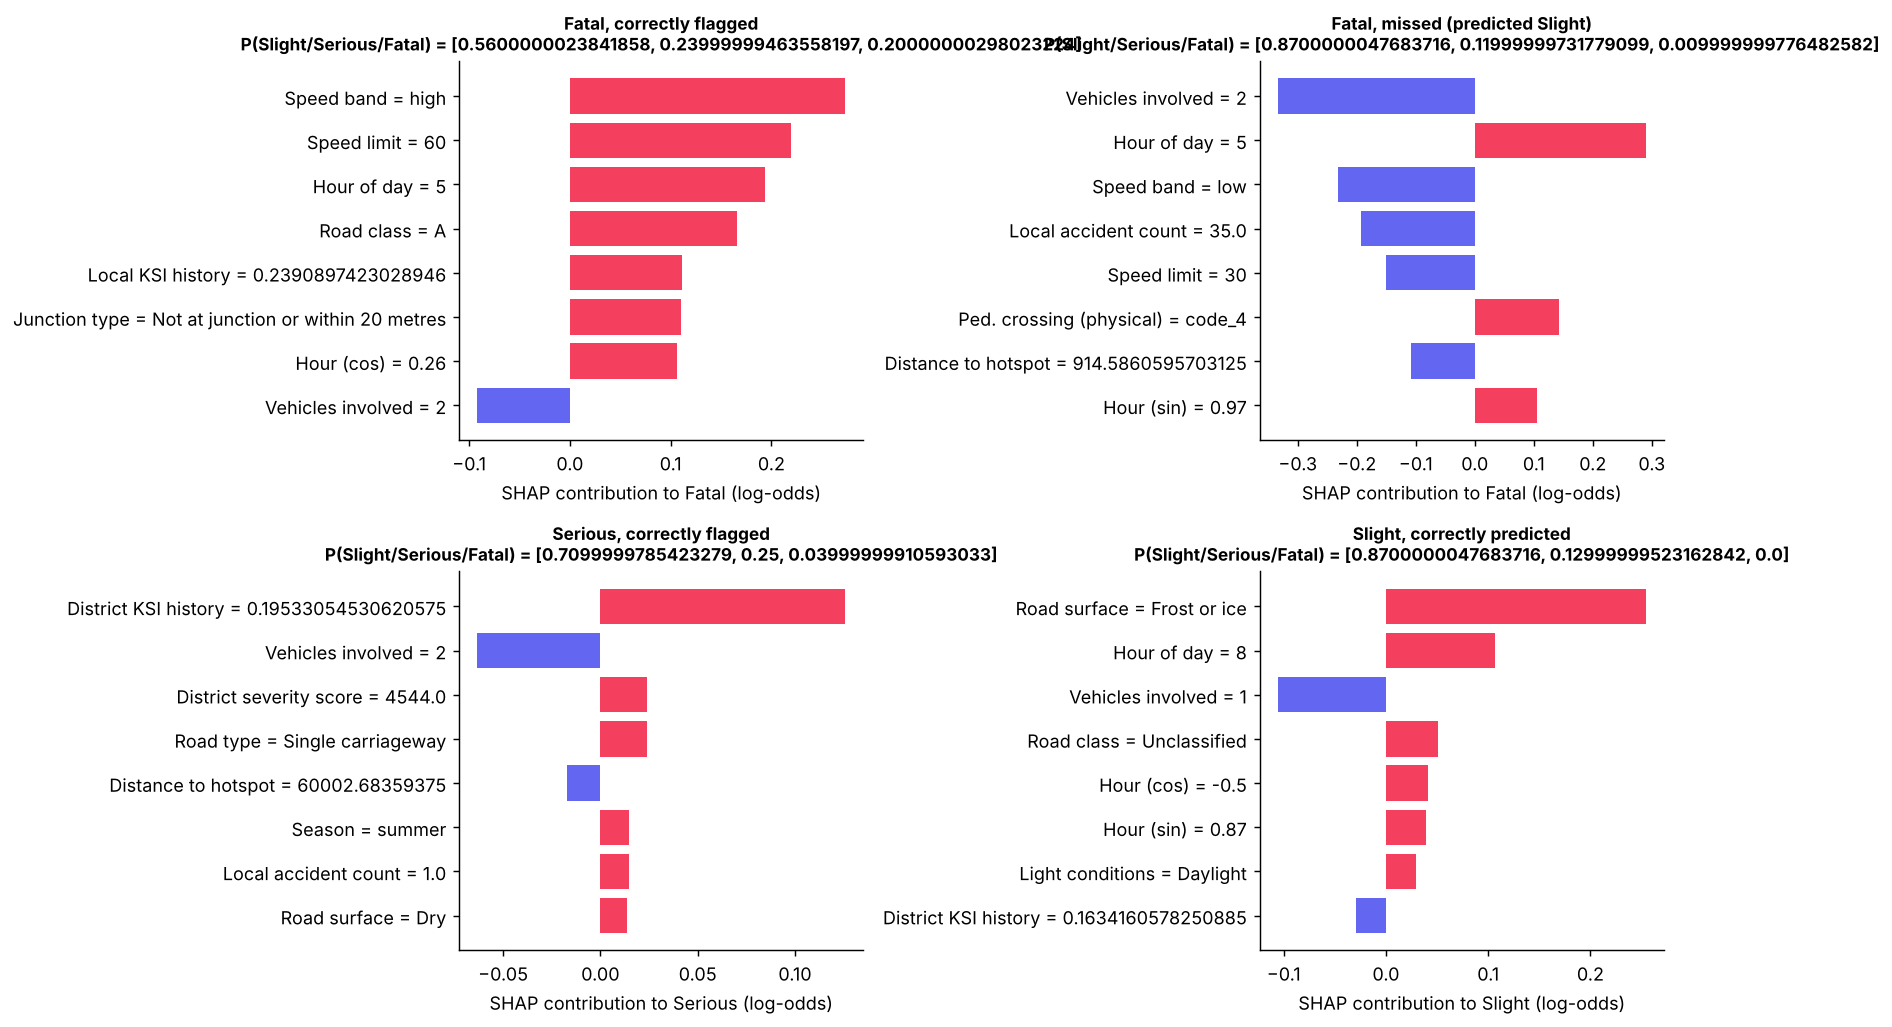

In [3]:
display(Image(F+'22_shap_dependence_fatal.png')); display(Image(F+'23_shap_local_cases.png'))

## Inside versus outside black spots

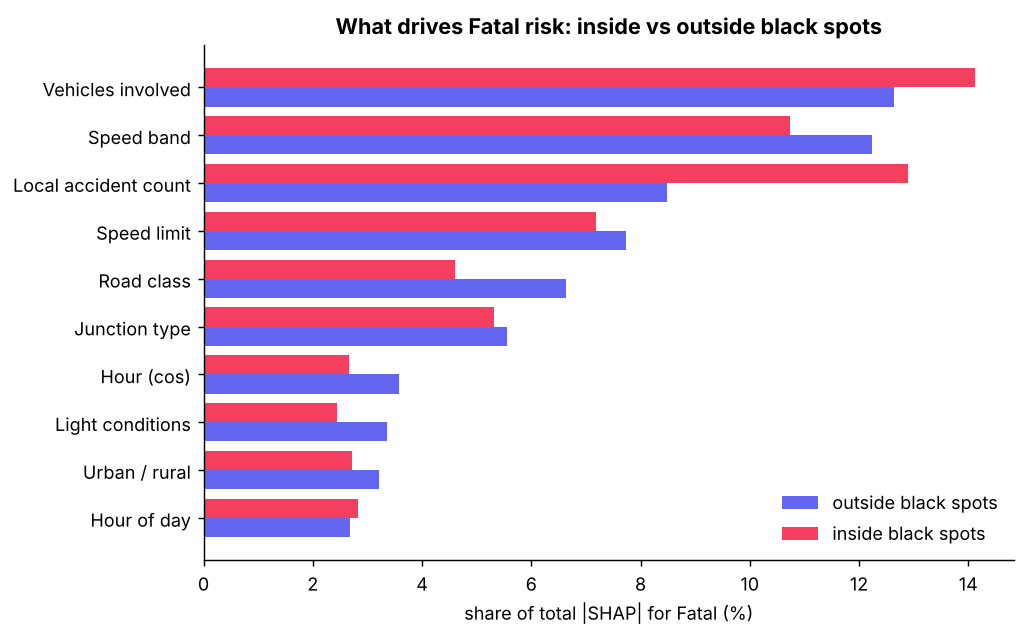

,inside,outside,inside_share,outside_share
n_vehicles,0.2812,0.2316,0.1413,0.1263
speed_band,0.2136,0.2245,0.1073,0.1225
h_cell_n,0.2565,0.1557,0.1289,0.0849
speed_limit,0.1430,0.1416,0.0718,0.0773
1st_Road_Class,0.0915,0.1216,0.0460,0.0663
Junction_Detail,0.1058,0.1017,0.0532,0.0555
hour_cos,0.0531,0.0655,0.0267,0.0357
Light_Conditions,0.0486,0.0616,0.0244,0.0336
Urban_or_Rural_Area,0.0541,0.0589,0.0272,0.0321
hour,0.0562,0.0491,0.0283,0.0268


In [4]:
display(Image(F+'24_shap_inside_vs_outside.png')); pd.read_csv(T+'shap_inside_vs_outside.csv', index_col=0).round(4).head(10)

## LIME versus SHAP
LIME fits a random local surrogate, so we report how stable its top features are across seeds.

In [5]:
pd.read_csv(T+'lime_vs_shap.csv')

,case,explained_class,shap_top5,lime_top5,shap_lime_top5_overlap,lime_stability_jaccard
0,6109,Fatal,"Speed band, Speed limit, Hour of day, Road cla...","Local authority, Vehicles involved, Speed limi...",0.4,0.547619
1,17,Serious,"District KSI history, Vehicles involved, Distr...","District KSI history, Vehicles involved, Local...",0.4,0.607143
2,0,Slight,"Road surface, Hour of day, Vehicles involved, ...","Vehicles involved, Carriageway hazards, Weathe...",0.2,0.383929
